# Progression-free survival prediction on RNA-seq embeddings and proteomics: 
## CoxPH model on BulkRNABERT embeddings and survival-associated protein expression in APOLLO-OV comparing whole and enriched tumor samples

**Paper:** [Proteogenomic analysis of enriched HGSOC tumor epithelium identifies prognostic signatures and therapeutic vulnerabilities](https://www.nature.com/articles/s41698-024-00519-8)

Apollo-OV: Bioinformatic Analysis of High-Grade Serous Ovarian Cancer (HGSOC)

## Survival RNA
- Obtain RNA expression data of both bulk "whole" tumor and laser microdissection "enriched" tumor cells
- Embed with bulkRNABERT model n=256 dims
- Join with usable progression-free survival (PFS) data
- Fit coxPH model for both Whole (70 cases) and Enriched (64 cases) data subsets:
    - 230/258 survival-associated transcripts mapped
    - X => BulkRNABERT embeddings, y => progression free survival in months
- Split data into train and test sets (~20%) and scale before using PCA (n=20 components)
- Utilize k-fold while fitting the cox model to reduce variability (kfolds = 5) and predict risk scores
- Calculate c-index between actual survival and predictions for each k-fold and report the mean
- Using a median risk score, partition the test sets for both Whole and Enriched into high risk (> median) and low risk (< median)
- Plot the curves with a Kaplan Meier survival style curve

## Survival Protein
- Repeat the same analysis as the RNA, expect with survival selected protein data (n=68) and PCA embeddings

## Survival RNA + Survival Protein (Combined Embeddings)
- Combine embeddings from the two modalities, fit coxPH model and recalculate c-index

## Comparative Hypothesis
- **Enriched tumor outperforms whole tumor** — k-folded C-index means of enriched tumor data should be higher than whole tumor across all modalities.

- **Multimodal embeddings improve survival prediction** — based on [Song et al. 2026](https://proceedings.mlr.press/v297/song26a.html), k-folded C-index means of combined embeddings should meet or exceed single-modality results..

## Section Index:
- [Initial Setup - Libraries and Functions](#Initial-Setup)
- [Selected Genes RNA-Sequencing](#Selected-Genes-RNA-Sequencing)
- [Selected Proteins Proteomics](#Selected-Proteins-Proteomics)
- [Combined RNA-SEQ and Proteomics](#Combined-RNA-SEQ-and-Proteomics)
- [Summary](#Summary)

Date: 09-16-26

# Initial-Setup

In [2]:
import pandas as pd
import os
import shutil
import numpy as np
import requests
import json
from tqdm import tqdm
import h5py
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold
from sksurv.nonparametric import kaplan_meier_estimator
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sksurv.linear_model import CoxPHSurvivalAnalysis
from sksurv.metrics import concordance_index_censored
from sksurv.linear_model import CoxPHSurvivalAnalysis
from sksurv.util import Surv
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sksurv.metrics import concordance_index_censored
from gen3.auth import Gen3Auth

Define directories for use in analysis

In [3]:
from pathlib import Path

# define home
home_dir = Path.home()

# define analysis and data directories
analysis_dir = home_dir / 'apollo-ov'
data_dir = analysis_dir / 'data'
model_data_dir = analysis_dir / 'model-data'

# create data and model data directory
data_dir.mkdir(parents=True, exist_ok=True)
model_data_dir.mkdir(parents=True, exist_ok=True)

## Preparation Details Prior to Analysis:

1. Apollo-OV RNA-Seq files were downloaded from the GDC using separate manifests for whole tumor and enriched tumor samples.
    - The GDC file manifest does not differentiate between enriched and whole tumor samples. Files were assigned to each sample type by querying the GDC API for each file's associated aliquot submitter ID (e.g. `<gene_id>_tumor_whole_RNA` vs `<gene_id>_tumor_enriched_RNA`).
3. Mapped 230 of 258 survival-associated transcripts from [Supplementary Data 7](https://media.springernature.com/original/springer-static/esm/art%3A10.1038%2Fs41698-024-00519-8/MediaObjects/41698_2024_519_MOESM10_ESM.xlsx) to ENSG IDs using three sources in priority order: [GENCODE v22](https://www.gencodegenes.org/human/release_22.html) (the annotation build used by the paper's pipeline), STAR augmented count file `gene_name` column, and [NCBI gene info synonyms](https://ftp.ncbi.nih.gov/gene/DATA/GENE_INFO/Mammalia/). The remaining 28 symbols could not be mapped due to gene annotation changes between GENCODE v22 and the GDC's current GENCODE v36 pipeline.
4. Embedded survival-associated gene expression profiles using [BulkRNABERT](https://github.com/StevenSong/BulkRNABert), masking all non-survival genes prior to embedding.

## Functions

In [4]:
# coxPH and k-fold combination function for RNA Embeddings
def coxph_kfold_eval(y_df, X_expr, n_splits=5, n_pca_components=10):
    """
    K-fold fit and evaluate a CoxPH model on survival RNA embeddings.
    - y_df: DataFrame with 'vital_status_b' and 'survivaltimeinmonths'
    - X_expr: DataFrame of features, **samples as rows**
    Returns: 
      - list of C-index (per split)
      - list of test risk scores arrays (per split)
      - list of structured y_test arrays (per split)
    """
    y = Surv.from_arrays(event=y_df['vital_status_b'].values,
                        time=y_df['survivaltimeinmonths'].values)
    X = X_expr

    kf = KFold(n_splits=n_splits, shuffle=True, random_state=120525)
    c_indices = []
    test_preds = []
    test_surv_arrays = []

    for train_index, test_index in kf.split(X):
        X_train, X_test = X[train_index], X[test_index]
        y_train, y_test = y[train_index], y[test_index]

        # Scale features
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        # PCA
        n_components = n_pca_components
        pca = PCA(n_components=n_components, random_state=120525)
        X_train_red = pca.fit_transform(X_train_scaled)
        X_test_red = pca.transform(X_test_scaled)

        # Fit Cox model
        cox_rna = CoxPHSurvivalAnalysis(alpha=0.1).fit(X_train_red, y_train)
        y_test_pred = cox_rna.predict(X_test_red)

        # C-index
        c_index = concordance_index_censored(
            event_indicator=y_test['event'],
            event_time=y_test['time'],
            estimate=y_test_pred
        )[0]
        c_indices.append(c_index)

        # Save extra data for survival plot
        test_preds.append(y_test_pred)
        test_surv_arrays.append(y_test)

    return c_indices, test_preds, test_surv_arrays

In [5]:
def get_kaplan_meier_steps(test_pred, y_test):
    """
    For one test set (risk scores and survival array), returns step curve data
    for high/low risk group (median split) using sksurv's kaplan_meier_estimator.
    Output: 
      - time_low, surv_low, time_high, surv_high
    """
    test_pred = np.array(test_pred)
    median_pred = np.median(test_pred)
    low_idx = test_pred <= median_pred
    high_idx = test_pred > median_pred

    # y_test is a structured array
    time_low, surv_low = kaplan_meier_estimator(
        y_test['event'][low_idx],
        y_test['time'][low_idx]
    )
    time_high, surv_high = kaplan_meier_estimator(
        y_test['event'][high_idx],
        y_test['time'][high_idx]
    )
    return time_low, surv_low, time_high, surv_high

# Selected-Genes-RNA-Sequencing

In [6]:
# Clinical data
clinical_df = pd.read_csv(model_data_dir / 'clinical.tsv', sep='\t')
print(f"PFS events: {clinical_df['pfs_event'].sum()}/{len(clinical_df)}")

PFS events: 60/70


### Enriched Tumor RNA-Seq coxPH Analysis

In [ ]:
auth_path = '/joyvan/pd/mc2dp-production-credentials.json'

auth = Gen3Auth(refresh_file=auth_path)

In [8]:
EMBEDDING_API = "https://mc2dp.data-commons.org/ai/vectorstore/collections"
COLLECTION = "rna-seq-survival"

def load_embeddings(project_id, subset):
    info = requests.get(f"{EMBEDDING_API}/{COLLECTION}", params={"counts": True}, auth=auth).json()
    r = requests.post(
        f"{EMBEDDING_API}/{COLLECTION}/search", auth=auth,
        json={"filters": {"project_id": project_id, "subset": subset},
              "top_k": info["available_embeddings_count"],
              "input": [1.0] + [0.0] * (info["dimensions"] - 1)},   # dummy query vector
    )
    r.raise_for_status()
    hits = [x["embedding"] for x in r.json()["embeddings"]]
    df = pd.DataFrame(np.array([h["vector"] for h in hits]),
                      index=[h["info"]["metadata"]["case_id"] for h in hits])
    df.index.name = "case_id"
    return df

# Load enriched tumor embeddings (keyed by case_id)
e_emb_df = load_embeddings("apollo-ov", "rna_enriched_tumor")
print(f"Embedding matrix shape: {e_emb_df.shape}")   # expect (64, 256)

Embedding matrix shape: (64, 256)


In [9]:
# Enriched
et_clinical_pfs = clinical_df.set_index('case_id').loc[e_emb_df.index]
et_y_df_pfs = et_clinical_pfs[['pfs_event', 'pfstimeinmonths']].rename(
    columns={'pfs_event': 'vital_status_b', 'pfstimeinmonths': 'survivaltimeinmonths'}
).dropna()
et_X_expr_pfs = e_emb_df.loc[et_y_df_pfs.index].values

c_indices_et_pfs, et_test_preds_pfs, et_test_surv_pfs = coxph_kfold_eval(et_y_df_pfs, et_X_expr_pfs, n_pca_components=20)
print(f"Enriched RNA PFS C-indices: {c_indices_et_pfs}")
print(f"Mean C-index: {np.mean(c_indices_et_pfs):.3f}")

Enriched RNA PFS C-indices: [np.float64(0.8450704225352113), np.float64(0.6153846153846154), np.float64(0.8181818181818182), np.float64(0.7792207792207793), np.float64(0.6515151515151515)]
Mean C-index: 0.742


### Whole Tumor RNA-Seq coxPH Analysis

In [10]:
# Load whole tumor embeddings (keyed by case_id)
w_emb_df = load_embeddings("apollo-ov", "rna_whole_tumor")
print(f"Embedding matrix shape: {w_emb_df.shape}")   # expect (64, 256)

Embedding matrix shape: (70, 256)


In [11]:
wt_clinical_pfs = clinical_df.set_index('case_id').loc[w_emb_df.index]
wt_y_df_pfs = wt_clinical_pfs[['pfs_event', 'pfstimeinmonths']].rename(
    columns={'pfs_event': 'vital_status_b', 'pfstimeinmonths': 'survivaltimeinmonths'}
).dropna()
wt_X_expr_pfs = w_emb_df.loc[wt_y_df_pfs.index].values

c_indices_wt_pfs, wt_test_preds_pfs, wt_test_surv_pfs = coxph_kfold_eval(wt_y_df_pfs, wt_X_expr_pfs, n_pca_components=20)
print(f"Whole RNA PFS C-indices: {c_indices_wt_pfs}")
print(f"Mean C-index: {np.mean(c_indices_wt_pfs):.3f}")

Whole RNA PFS C-indices: [np.float64(0.6593406593406593), np.float64(0.5280898876404494), np.float64(0.7954545454545454), np.float64(0.625), np.float64(0.6075949367088608)]
Mean C-index: 0.643


### Kaplan-Meier Risk Stratification — RNA-Seq

In [12]:
# Enriched tumor pooled test preds & survival arrays
enriched_rna_preds = np.concatenate(et_test_preds_pfs)
enriched_rna_surv = np.concatenate(et_test_surv_pfs)

# Whole tumor pooled test preds & survival arrays
whole_rna_preds = np.concatenate(wt_test_preds_pfs)
whole_rna_surv = np.concatenate(wt_test_surv_pfs)

# Enriched tumor curves
time_low_enriched, surv_low_enriched, time_high_enriched, surv_high_enriched = get_kaplan_meier_steps(
    enriched_rna_preds, enriched_rna_surv)

# Whole tumor curves
time_low_whole, surv_low_whole, time_high_whole, surv_high_whole = get_kaplan_meier_steps(
    whole_rna_preds, whole_rna_surv)

In [13]:
from sksurv.compare import compare_survival

def add_logrank_pvalue(ax, y_test, test_pred):
    test_pred = np.array(test_pred)
    median_pred = np.median(test_pred)
    groups = (test_pred > median_pred).astype(int)
    chi2, p_value = compare_survival(y_test, groups)
    ax.text(0.05, 0.05, f'p = {p_value:.3f}', transform=ax.transAxes,
            fontsize=10, verticalalignment='bottom',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

### Plotting Kaplan-Meier

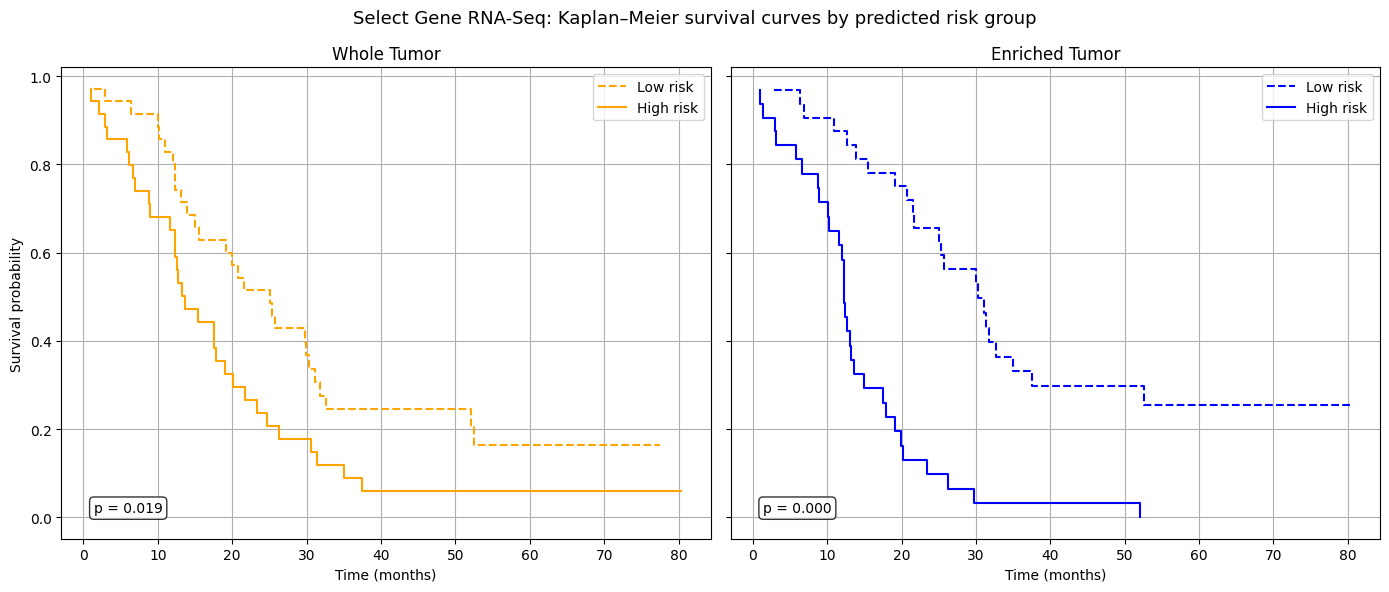

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Whole tumor
ax1.step(time_low_whole, surv_low_whole, where="post", label="Low risk", color='orange', linestyle="--")
ax1.step(time_high_whole, surv_high_whole, where="post", label="High risk", color='orange')
ax1.set_title("Whole Tumor")
ax1.set_xlabel("Time (months)")
ax1.set_ylabel("Survival probability")
ax1.legend()
ax1.grid(True)
add_logrank_pvalue(ax1, whole_rna_surv, whole_rna_preds)

# Enriched tumor
ax2.step(time_low_enriched, surv_low_enriched, where="post", label="Low risk", color='blue', linestyle="--")
ax2.step(time_high_enriched, surv_high_enriched, where="post", label="High risk", color='blue')
ax2.set_title("Enriched Tumor")
ax2.set_xlabel("Time (months)")
ax2.legend()
ax2.grid(True)
add_logrank_pvalue(ax2, enriched_rna_surv, enriched_rna_preds)

fig.suptitle("Select Gene RNA-Seq: Kaplan–Meier survival curves by predicted risk group", fontsize=13)
plt.tight_layout()
plt.show()

In [15]:
from sksurv.compare import compare_survival
import numpy as np

# Pool predictions already done above
# whole_rna_preds, whole_rna_surv, enriched_rna_preds, enriched_rna_surv

# Get high risk indices for each
whole_high_idx = np.array(whole_rna_preds) > np.median(whole_rna_preds)
enriched_high_idx = np.array(enriched_rna_preds) > np.median(enriched_rna_preds)

# Pull high risk survival arrays
whole_high_surv = whole_rna_surv[whole_high_idx]
enriched_high_surv = enriched_rna_surv[enriched_high_idx]

# Combine and create group labels (0=whole, 1=enriched)
combined_surv = np.concatenate([whole_high_surv, enriched_high_surv])
groups = np.array([0] * whole_high_surv.shape[0] + [1] * enriched_high_surv.shape[0])

chi2, p_value = compare_survival(combined_surv, groups)
print(f"High risk Whole vs Enriched log-rank p = {p_value:.3f}")

High risk Whole vs Enriched log-rank p = 0.133


# Selected-Proteins-Proteomics

To run the next section download Table 1 from the paper's supplementary data.
Protein Expression Supplementary Data: [link](https://media.springernature.com/original/springer-static/esm/art%3A10.1038%2Fs41698-024-00519-8/MediaObjects/41698_2024_519_MOESM4_ESM.xlsx)
Bulk (Whole) Tumor is located in Table 1A
Enriched Tumor is located in Table 1B

Place this into the `data_dir` which is `~/apollo-ov/data/`

In [ ]:
# Load proteomics, deduplicate protein names, transpose samples to rows
supp_path = data_dir / "41698_2024_519_MOESM4_ESM.xlsx"

# Sheet 1 (1A) = bulk (whole) tumor, sheet 2 (1B) = enriched tumor
sheets = pd.read_excel(supp_path, sheet_name=[0, 1])   # add header=N if there are title rows above the table
w_protein_expr, e_protein_expr = sheets[0], sheets[1]

w_protein_expr_t = (w_protein_expr
    .set_index('Gene')
    .drop(columns=['Accession', 'Description'])
    .loc[~w_protein_expr.set_index('Gene').index.duplicated(keep='first')]
    .T
    .reset_index()
    .rename(columns={'index': 'protein_sample_id'}))

e_protein_expr_t = (e_protein_expr
    .set_index('Gene')
    .drop(columns=['Accession', 'Description'])
    .loc[~e_protein_expr.set_index('Gene').index.duplicated(keep='first')]
    .T
    .reset_index()
    .rename(columns={'index': 'protein_sample_id'}))

print(f"Whole protein shape: {w_protein_expr_t.shape}")
print(f"Enriched protein shape: {e_protein_expr_t.shape}")

# Merge with clinical
w_protein_expr_clinical = pd.merge(clinical_df, w_protein_expr_t,
                                    left_on='AID', right_on='protein_sample_id', how='inner')
e_protein_expr_clinical = pd.merge(clinical_df, e_protein_expr_t,
                                    left_on='AID', right_on='protein_sample_id', how='inner')

print(f"Whole protein+clinical: {w_protein_expr_clinical.shape}")
print(f"Enriched protein+clinical: {e_protein_expr_clinical.shape}")

Whole protein shape: (70, 7533)
Enriched protein shape: (70, 7843)
Whole protein+clinical: (70, 7541)
Enriched protein+clinical: (70, 7851)


In [17]:
#grab survival proteins from supp data 7 and filter down

sel_protein_df = pd.read_excel(data_dir / '41698_2024_519_MOESM10_ESM-7.xlsx')
sel_protein_df = sel_protein_df[sel_protein_df['Candidate_Transcript|ProteinLevel'] == 'Protein']
survival_proteins = sel_protein_df['GeneID'].tolist()

print(f"Survival proteins: {len(survival_proteins)}")

# Filter merged dataframes to survival proteins + clinical columns before dropping
keep_cols = list(clinical_df.columns) + ['protein_sample_id'] + \
            [p for p in survival_proteins if p in w_protein_expr_clinical.columns]
w_protein_expr_clinical = w_protein_expr_clinical[keep_cols]

keep_cols = list(clinical_df.columns) + ['protein_sample_id'] + \
            [p for p in survival_proteins if p in e_protein_expr_clinical.columns]
e_protein_expr_clinical = e_protein_expr_clinical[keep_cols]

print(f"Whole tumor survival proteins found: {w_protein_expr_clinical.shape[1] - len(clinical_df.columns) - 1}")
print(f"Enriched tumor survival proteins found: {e_protein_expr_clinical.shape[1] - len(clinical_df.columns) - 1}")

# Format data for PCA
drop_columns = list(clinical_df.columns) + ['protein_sample_id']

w_protein_expr_data = w_protein_expr_clinical.drop(columns=drop_columns)
print(w_protein_expr_data.head(2))

e_protein_expr_data = e_protein_expr_clinical.drop(columns=drop_columns)

Survival proteins: 68
Whole tumor survival proteins found: 63
Enriched tumor survival proteins found: 68
      ABCD4      AGRN     AP3M1   B4GALT1     CADM1      CGAS     CLIC2  \
0  0.540298  0.104897  0.057554  0.772818 -0.268291  0.695647  0.089248   
1  0.052568  0.629517 -0.413244 -0.136317 -0.167859  0.145453 -0.709408   

     CYP1B1   CYP51A1    EIF2S3  ...      TBCD   TMEM109   TMEM131     TMUB1  \
0 -0.063776  1.419573 -0.552512  ... -0.250537 -0.336707 -0.380632  0.730053   
1 -0.768824 -0.763439 -0.294465  ... -0.741311 -0.873967  0.178550  0.150823   

   TRAPPC6B      TRIO     UBE4A      URB1     VTI1B     XRCC4  
0 -0.418623 -0.524841  0.652293 -0.458004 -0.020953  0.341099  
1 -0.224291  0.001573 -0.242704 -0.018571 -0.223859  0.580133  

[2 rows x 63 columns]


In [18]:
# coxPH and k-fold combination function for Proteomics

def protein_coxph_kfold_eval(y_df, X_expr, n_splits=5, n_pca_components=10):
    """
    K-fold fit and evaluate a CoxPH model on survival protein expression.
    - y_df: DataFrame with 'vital_status_b' and 'survivaltimeinmonths'
    - X_expr: DataFrame of features, **samples as rows**
    - n_splits: folds for K-fold
    - n_pca_components: number of PCA dimensions
    Returns: list of C-index (per split)
    """
    # Survival structured arrays
    y = Surv.from_arrays(event=y_df['vital_status_b'].values,
                        time=y_df['survivaltimeinmonths'].values)
    X = X_expr

    kf = KFold(n_splits=n_splits, shuffle=True, random_state=120525)
    c_indices = []
    test_preds = []
    test_surv_arrays = []

    for train_index, test_index in kf.split(X):
        X_train, X_test = X.iloc[train_index, :], X.iloc[test_index, :]
        y_train, y_test = y[train_index], y[test_index]

        # Scale features
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        # PCA
        n_components = n_pca_components
        pca = PCA(n_components=n_components, random_state=120525)
        X_train_red = pca.fit_transform(X_train_scaled)
        X_test_red = pca.transform(X_test_scaled)

        # Fit Cox model
        cox_rna = CoxPHSurvivalAnalysis(alpha=0.1).fit(X_train_red, y_train)
        y_test_pred = cox_rna.predict(X_test_red)

        # C-index
        c_index = concordance_index_censored(
            event_indicator=y_test['event'],
            event_time=y_test['time'],
            estimate=y_test_pred
        )[0]
        c_indices.append(c_index)
        #print(c_index)

        # Save extra data for survival plot
        test_preds.append(y_test_pred)
        test_surv_arrays.append(y_test)

    return c_indices, test_preds, test_surv_arrays

In [19]:
clinical_cols = clinical_df.columns.tolist() + ['protein_sample_id']

w_X = w_protein_expr_clinical.drop(columns=clinical_cols, errors='ignore')
e_X = e_protein_expr_clinical.drop(columns=clinical_cols, errors='ignore')

print(f"w_X shape: {w_X.shape}")
print(f"e_X shape: {e_X.shape}")
print(f"w_X dtypes: {w_X.dtypes.value_counts()}")

w_X shape: (70, 63)
e_X shape: (70, 68)
w_X dtypes: float64    63
Name: count, dtype: int64


In [20]:
# Whole tumor
clinical_cols = clinical_df.columns.tolist() + ['protein_sample_id']

# Whole tumor
w_X = w_protein_expr_clinical.drop(columns=clinical_cols, errors='ignore')
w_y = w_protein_expr_clinical[['pfs_event', 'pfstimeinmonths']].rename(
    columns={'pfs_event': 'vital_status_b', 'pfstimeinmonths': 'survivaltimeinmonths'}
)
c_indices_w_prot, w_prot_preds, w_prot_surv = protein_coxph_kfold_eval(w_y, w_X, n_pca_components=20)
print(f"Whole protein mean C-index: {np.mean(c_indices_w_prot):.3f}")

# Enriched tumor
e_X = e_protein_expr_clinical.drop(columns=clinical_cols, errors='ignore')
e_y = e_protein_expr_clinical[['pfs_event', 'pfstimeinmonths']].rename(
    columns={'pfs_event': 'vital_status_b', 'pfstimeinmonths': 'survivaltimeinmonths'}
)
c_indices_e_prot, e_prot_preds, e_prot_surv = protein_coxph_kfold_eval(e_y, e_X, n_pca_components=20)
print(f"Enriched protein mean C-index: {np.mean(c_indices_e_prot):.3f}")

Whole protein mean C-index: 0.690
Enriched protein mean C-index: 0.712


In [21]:
# Whole tumor pooled test preds & survival arrays
whole_preds_protein = np.concatenate(w_prot_preds)
whole_surv_protein = np.concatenate(w_prot_surv)

# Enriched tumor pooled test preds & survival arrays
enriched_preds_protein = np.concatenate(e_prot_preds)
enriched_surv_protein = np.concatenate(e_prot_surv)

In [22]:
# Whole tumor curves
time_low_whole, surv_low_whole, time_high_whole, surv_high_whole = get_kaplan_meier_steps(
    whole_preds_protein, whole_surv_protein)

# Enriched tumor curves
time_low_enriched, surv_low_enriched, time_high_enriched, surv_high_enriched = get_kaplan_meier_steps(
    enriched_preds_protein, enriched_surv_protein)

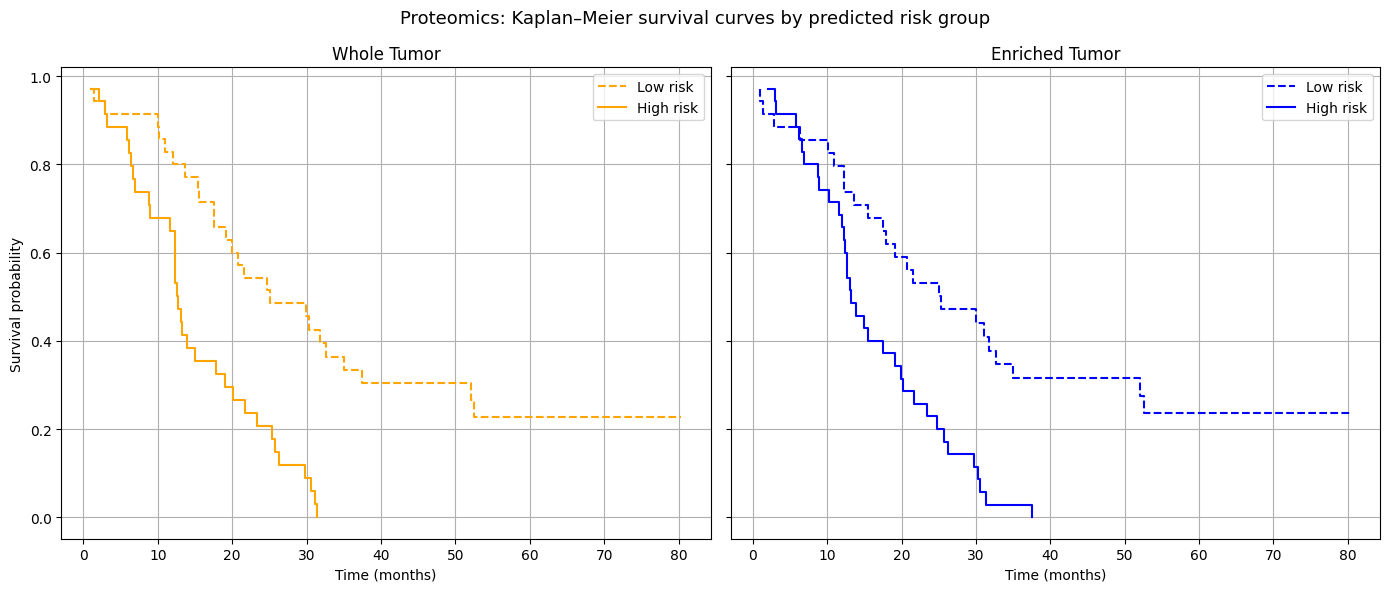

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Whole tumor
ax1.step(time_low_whole, surv_low_whole, where="post", label="Low risk", color='orange', linestyle="--")
ax1.step(time_high_whole, surv_high_whole, where="post", label="High risk", color='orange')
ax1.set_title("Whole Tumor")
ax1.set_xlabel("Time (months)")
ax1.set_ylabel("Survival probability")
ax1.legend()
ax1.grid(True)

# Enriched tumor
ax2.step(time_low_enriched, surv_low_enriched, where="post", label="Low risk", color='blue', linestyle="--")
ax2.step(time_high_enriched, surv_high_enriched, where="post", label="High risk", color='blue')
ax2.set_title("Enriched Tumor")
ax2.set_xlabel("Time (months)")
ax2.legend()
ax2.grid(True)

fig.suptitle("Proteomics: Kaplan–Meier survival curves by predicted risk group", fontsize=13)
plt.tight_layout()
plt.show()

## Combined Analysis

### Merge RNA and Protein Embeddings and recalculate C-index

In [24]:
case_to_aid = clinical_df.set_index('case_id')['AID'].to_dict()

wt_aid_order = [case_to_aid[c] for c in wt_y_df_pfs.index.tolist()]
et_aid_order = [case_to_aid[c] for c in et_y_df_pfs.index.tolist()]

w_protein_expr_clinical_aligned = w_protein_expr_clinical.set_index('AID').loc[wt_aid_order]
e_protein_expr_clinical_aligned = e_protein_expr_clinical.set_index('AID').loc[et_aid_order]

drop_columns = [c for c in clinical_df.columns if c != 'AID'] + ['protein_sample_id', 'case_id']
w_protein_expr_data = w_protein_expr_clinical_aligned.drop(columns=drop_columns, errors='ignore')
e_protein_expr_data = e_protein_expr_clinical_aligned.drop(columns=drop_columns, errors='ignore')

print(f"Whole protein data shape: {w_protein_expr_data.shape}")
print(f"Enriched protein data shape: {e_protein_expr_data.shape}")
print(f"RNA whole shape: {wt_X_expr_pfs.shape}")
print(f"RNA enriched shape: {et_X_expr_pfs.shape}")

Whole protein data shape: (70, 63)
Enriched protein data shape: (64, 68)
RNA whole shape: (70, 256)
RNA enriched shape: (64, 256)


In [25]:
def coxph_combined_kfold_eval(rna_embeddings, protein_embeddings, y_df, n_splits=5, n_pca_components=10):
    """
    Combine RNA (numpy array) + protein (DataFrame) embeddings, fit CoxPH with k-folds & PCA.
    Arguments:
        rna_embeddings: numpy array (samples x features)
        protein_embeddings: pandas DataFrame (samples x features)
        y_df: DataFrame with 'vital_status_b' and 'survivaltimeinmonths' columns
        n_splits: # k-fold splits
        n_pca_components: # PCA components
    Returns:
        c_indices: list of C-index (per split)
    """

    # Ensure both are numpy arrays
    rna_array = np.asarray(rna_embeddings)
    protein_array = protein_embeddings.values

    X_expr = np.concatenate([rna_array, protein_array], axis=1)

    # Survival target struct
    y = Surv.from_arrays(
        event=y_df['vital_status_b'].values,
        time=y_df['survivaltimeinmonths'].values
    )

    kf = KFold(n_splits=n_splits, shuffle=True, random_state=120525)
    c_indices = []
    test_preds = []
    test_surv_arrays = []

    for train_index, test_index in kf.split(X_expr):
        X_train, X_test = X_expr[train_index], X_expr[test_index]
        y_train, y_test = y[train_index], y[test_index]

        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        pca = PCA(n_components=n_pca_components, random_state=120525)
        X_train_red = pca.fit_transform(X_train_scaled)
        X_test_red = pca.transform(X_test_scaled)

        cox_model = CoxPHSurvivalAnalysis(alpha=0.1).fit(X_train_red, y_train)
        y_test_pred = cox_model.predict(X_test_red)

        c_index = concordance_index_censored(
            event_indicator=y_test['event'],
            event_time=y_test['time'],
            estimate=y_test_pred
        )[0]
        c_indices.append(c_index)

        # Save extra data for survival plot
        test_preds.append(y_test_pred)
        test_surv_arrays.append(y_test)

    return c_indices, test_preds, test_surv_arrays

In [26]:
# Whole tumor combined
w_combined, w_combined_preds, w_combined_surv = coxph_combined_kfold_eval(
    wt_X_expr_pfs, w_protein_expr_data, wt_y_df_pfs, n_pca_components=20
)
print("Whole tumor c-index list:", w_combined)
print(f"Whole mean c-index: {np.mean(w_combined):.3f}")

# Enriched tumor combined
e_combined, e_combined_preds, e_combined_surv = coxph_combined_kfold_eval(
    et_X_expr_pfs, e_protein_expr_data, et_y_df_pfs, n_pca_components=20
)
print("Enriched tumor c-index list:", e_combined)
print(f"Enriched mean c-index: {np.mean(e_combined):.3f}")

Whole tumor c-index list: [np.float64(0.6483516483516484), np.float64(0.5730337078651685), np.float64(0.8636363636363636), np.float64(0.6363636363636364), np.float64(0.5949367088607594)]
Whole mean c-index: 0.663
Enriched tumor c-index list: [np.float64(0.8873239436619719), np.float64(0.5641025641025641), np.float64(0.8939393939393939), np.float64(0.7532467532467533), np.float64(0.6515151515151515)]
Enriched mean c-index: 0.750


In [27]:
# Whole tumor pooled test preds & survival arrays
all_whole_preds_comb = np.concatenate(w_combined_preds)
all_whole_surv_comb = np.concatenate(w_combined_surv)

# Enriched tumor pooled test preds & survival arrays
all_enriched_preds_comb = np.concatenate(e_combined_preds)
all_enriched_surv_comb = np.concatenate(e_combined_surv)

In [28]:
# Whole tumor curves
time_low_whole, surv_low_whole, time_high_whole, surv_high_whole = get_kaplan_meier_steps(
    all_whole_preds_comb, all_whole_surv_comb)

# Enriched tumor curves
time_low_enriched, surv_low_enriched, time_high_enriched, surv_high_enriched = get_kaplan_meier_steps(
    all_enriched_preds_comb, all_enriched_surv_comb)

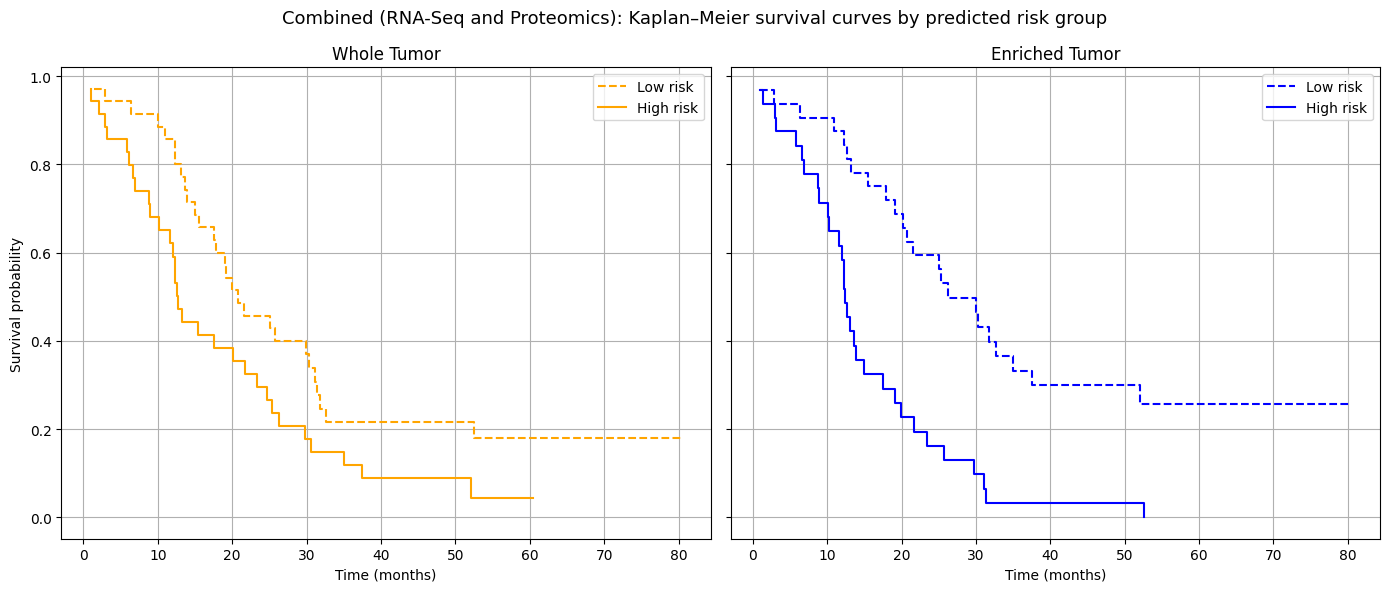

In [29]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Whole tumor
ax1.step(time_low_whole, surv_low_whole, where="post", label="Low risk", color='orange', linestyle="--")
ax1.step(time_high_whole, surv_high_whole, where="post", label="High risk", color='orange')
ax1.set_title("Whole Tumor")
ax1.set_xlabel("Time (months)")
ax1.set_ylabel("Survival probability")
ax1.legend()
ax1.grid(True)

# Enriched tumor
ax2.step(time_low_enriched, surv_low_enriched, where="post", label="Low risk", color='blue', linestyle="--")
ax2.step(time_high_enriched, surv_high_enriched, where="post", label="High risk", color='blue')
ax2.set_title("Enriched Tumor")
ax2.set_xlabel("Time (months)")
ax2.legend()
ax2.grid(True)

fig.suptitle("Combined (RNA-Seq and Proteomics): Kaplan–Meier survival curves by predicted risk group", fontsize=13)
plt.tight_layout()
plt.show()

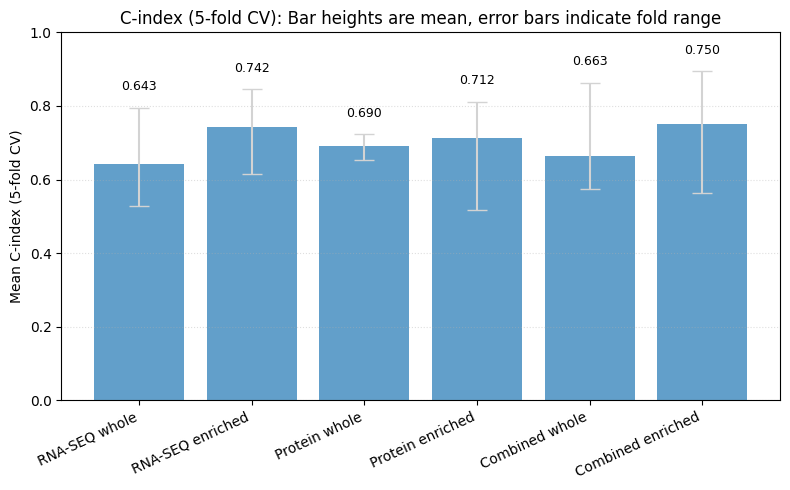

In [30]:
# Summary of c-index (5-fold) scores

# RNA-SEQ
rna_whole = c_indices_wt_pfs
rna_enriched = c_indices_et_pfs

# Proteomics
pro_whole = c_indices_w_prot
pro_enriched = c_indices_e_prot

# Combined
comb_whole = w_combined
comb_enriched = e_combined

# Group labels and values
labels = [
    "RNA-SEQ whole",
    "RNA-SEQ enriched",
    "Protein whole",
    "Protein enriched",
    "Combined whole",
    "Combined enriched"
]
data = [rna_whole, rna_enriched, pro_whole, pro_enriched, comb_whole, comb_enriched]
means = [np.mean(x) for x in data]
mins = [np.min(x) for x in data]
maxs = [np.max(x) for x in data]

errors = [(mean - min_val, max_val - mean) for mean, min_val, max_val in zip(means, mins, maxs)]
lower_errors, upper_errors = zip(*errors)

plt.figure(figsize=(8,5))
x = np.arange(len(labels))

bars = plt.bar(x, means, yerr=[lower_errors, upper_errors], capsize=7, alpha=0.7,
               error_kw=dict(ecolor='lightgrey', elinewidth=1.5, capsize=7))

# Add mean c-index at top of plot above error bars
for bar, mean, max_val in zip(bars, means, maxs):
    plt.text(bar.get_x() + bar.get_width() / 2, max_val + 0.04,
             f'{mean:.3f}', ha='center', va='bottom', fontsize=9)

plt.xticks(x, labels, rotation=25, ha='right')
plt.ylabel("Mean C-index (5-fold CV)")
plt.title("C-index (5-fold CV): Bar heights are mean, error bars indicate fold range")
plt.ylim(0, 1)
plt.grid(axis='y', linestyle=':', alpha=0.4)
plt.tight_layout()
plt.show()

# Summary

#### Mean c-index (5-fold)
| Modality | Whole Tumor | Enriched Tumor |
|----------|-------------|----------------|
| RNA-seq | 0.671 | 0.701 |
| Proteomics | 0.690 | 0.712 |
| Combined | 0.685 | 0.711 |

**Both hypotheses were supported by the cross-validated CoxPH results:**

1. Enriched tumor outperformed whole tumor across all three modalities, with the most pronounced advantage in RNA-seq embeddings.
2. Combined RNA-seq and proteomics embeddings met or exceeded single-modality C-index results across both tumor types.